# 06f: Deep Learning Comparison, Diagnostics, and Summary

This is one of six notebooks covering the deep-learning (FNN/LSTM/TCN) side of this thesis:

- `06a_sequence_investigation.ipynb` -- jobs-per-user distribution, the sequence-length choice, padding policy, the sequence-construction leakage test, and F-DATA/PM100 lag-1 autocorrelation; also holds the deep-learning feature-set explanation shared by the notebooks below.
- `06b_model_architectures.ipynb` -- the FNN/SequenceLSTM/SequenceTCN/`_CausalConvBlock`/FlatDataset/SequenceDataset class definitions, documented layer by layer, an equivalence check against `src/models.py`, architecture diagrams, the training configuration, and a checkpoint-match check across all 18 (combination, architecture) pairs.
- `06c_dl_power.ipynb` -- the real FNN/LSTM/TCN sweep for F-DATA power and PM100 power.
- `06d_dl_duration.ipynb` -- the same for F-DATA duration and PM100 duration.
- `06e_dl_memory.ipynb` -- the same for F-DATA memory and PM100 memory (`pm100_memory_c4`).
- `06f_dl_comparison.ipynb` -- the F-DATA duration/memory raw-space collapse diagnostic (including the three-user inspection), the same-features classical-ML control, and the six-combination summary against classical ML.

**The DL feature set is not identical to classical ML's (05/05b/05c).** Three column families are dropped for the DL models specifically, scoped to the deep-learning pipeline only -- classical ML's own already-adopted results are untouched:
- Absolute epoch-timestamp columns (`adt_epoch`/`qdt_epoch`/`schedsdt_epoch` for F-DATA, `submit_time_epoch`/`eligible_time_epoch` for PM100) -- standardized on tune_train, a chronologically-later test period's values land several std devs out of range, which a standardized neural net cannot extrapolate through (trees tolerate this fine via boundary splits).
- Per-split `pd.factorize()`-coded categorical columns (`jobenv_req_code` for F-DATA; `partition_code`/`qos_code`/`shared_code`/`group_id_code` for PM100) -- the integer code is order-of-first-appearance WITHIN each split, so the same real category can get a different code in train vs test. Replaced, not just dropped: one-hot encoded instead, fit on the train+test population combined so both splits get identical dummy columns.
- Per-split user-frequency columns (`usr_freq` for F-DATA, `user_id_freq` for PM100) -- same issue class, a user's test-period job count has nothing to do with their train-period count.

See `src/dl_data.py`'s `load_combo` for the real implementation of all three.

This notebook loads the real test-prediction artifacts notebooks 06c/06d/06e wrote (`data/interim/notebook06_results/`) rather than recomputing or retraining anything -- `run_pair` is never called here. It covers: the F-DATA duration/memory raw-space collapse diagnostic (including a per-user inspection of the three users responsible for most of it), a same-features classical-ML control (fits LightGBM/XGBoost on the exact deep-learning feature set and split), and the full six-combination summary against classical ML's own already-adopted numbers.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import sys
sys.path.append("..")

import pathlib
import time

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import r2_score

from src import features, metrics, splits
from src.dl_data import load_combo
from src.dl_pipeline import load_pair_artifacts, ARCHITECTURES

pd.set_option("display.width", 160)

ALL_COMBOS = ["fdata_power", "fdata_duration", "fdata_memory",
              "pm100_power", "pm100_duration", "pm100_memory_c4"]

all_results = {}
for combo in ALL_COMBOS:
    all_results[combo] = {arch: load_pair_artifacts(combo, arch) for arch in ARCHITECTURES}
print(f"Loaded real test-prediction artifacts for {len(ALL_COMBOS)} combinations x "
      f"{len(ARCHITECTURES)} architectures ({len(ALL_COMBOS) * len(ARCHITECTURES)} pairs), "
      f"written by notebooks 06c_dl_power.ipynb, 06d_dl_duration.ipynb, and "
      f"06e_dl_memory.ipynb -- nothing is recomputed in this notebook.")


Loaded real test-prediction artifacts for 6 combinations x 3 architectures (18 pairs), written by notebooks 06c_dl_power.ipynb, 06d_dl_duration.ipynb, and 06e_dl_memory.ipynb -- nothing is recomputed in this notebook.


## Diagnosing the F-DATA duration/memory raw-space collapse

F-DATA duration and F-DATA memory's LSTM/TCN showed a sharp log-space-vs-raw-space split in notebooks 06d_dl_duration.ipynb and 06e_dl_memory.ipynb: reasonable log-space R2 but catastrophic raw-space R2 (duration: roughly -3.6/-3.1; memory: roughly 0.39/0.40). This tests the concentration of squared error directly -- is it a few rows, a few users, or spread out -- for LSTM, TCN, AND FNN on both targets (FNN included for comparison, since it does not show the collapse). Uses the real test predictions and user ids loaded above (`all_results["fdata_duration"]`/`all_results["fdata_memory"]`, written by 06d/06e) -- nothing is retrained, and the stored sweep results are not altered; this only reports on them.

In [2]:
test_user_ids = {combo: all_results[combo]["FNN"]["user_ids"]
                 for combo in ["fdata_duration", "fdata_memory"]}

concentration_rows = []
for combo in ["fdata_duration", "fdata_memory"]:
    user_ids = test_user_ids[combo]
    for arch in ["FNN", "LSTM", "TCN"]:
        r = all_results[combo][arch]
        y_true = np.asarray(r["y_test_raw"], dtype=float)
        y_pred = np.asarray(r["preds_raw"], dtype=float)
        se = (y_true - y_pred) ** 2
        total_se = se.sum()
        order = np.argsort(-se)

        def se_share(n):
            return 100 * se[order[:n]].sum() / total_se

        n_test = len(y_true)
        top1000_idx = order[:1000]
        top1000_users = np.unique(user_ids[top1000_idx])
        # share of TOTAL squared error coming from these users' rows (ALL their rows, not
        # just their rows that happen to be in the top 1000) -- a genuinely different
        # question from "top1000_se_share" above: are the big errors concentrated in a few
        # USERS (across many of their jobs), or scattered across many different users each
        # contributing a single bad row?
        is_top1000_user = np.isin(user_ids, top1000_users)
        users_se_share = 100 * se[is_top1000_user].sum() / total_se

        raw_r2_excl_top1000 = r2_score(np.delete(y_true, top1000_idx), np.delete(y_pred, top1000_idx))

        concentration_rows.append(dict(
            combo=combo, arch=arch, n_test=n_test,
            se_share_top10_pct=se_share(10), se_share_top100_pct=se_share(100),
            se_share_top1000_pct=se_share(1000), se_share_top0_1pct_pct=se_share(max(1, n_test // 1000)),
            raw_R2_full=r["raw_metrics"]["R2"], raw_R2_excl_top1000=raw_r2_excl_top1000,
            n_distinct_users_top1000=len(top1000_users),
            those_users_total_se_share_pct=users_se_share,
        ))

concentration_df = pd.DataFrame(concentration_rows).set_index(["combo", "arch"])
display(concentration_df.round(4))


n_test  se_share_top10_pct  se_share_top100_pct  se_share_top1000_pct  se_share_top0_1pct_pct  raw_R2_full  raw_R2_excl_top1000  \
combo          arch                                                                                                                                     
fdata_duration FNN   6992514              0.0598               0.5603                4.3894                 18.7467       0.7661               0.7738   
               LSTM  6992514              0.0821               0.5849                4.8028                 20.0563      -3.5850              -3.3958   
               TCN   6992514              0.0888               0.6468                4.7858                 19.9142      -3.1166              -2.9397   
fdata_memory   FNN   6992514              0.0148               0.1286                1.1012                  5.6217       0.8000               0.8020   
               LSTM  6992514              0.1450               0.6441                2.0572                  7.7780       0.3846               0.3970   
               TCN   6992514              0.0892               0.3668                1.5267                  6.9391       0.3965               0.4054   

                     n_distinct_users_top1000  those_users_total_se_share_pct  
combo          arch                                                            
fdata_duration FNN                        132                         59.5199  
               LSTM                         3                         80.6715  
               TCN                          3                         82.3839  
fdata_memory   FNN                        152                         53.4153  
               LSTM                        41                         57.5162  
               TCN                         49                         55.8600

**The numbers above show the error is concentrated in a small number of USERS, not spread out -- and the degree of concentration is what separates F-DATA duration's catastrophic collapse from F-DATA memory's milder one.**

**F-DATA duration -- concentrated in just 3 users:** FNN's top-1000-squared-error rows involve 132 distinct users, whose combined squared error (across ALL their rows, not just their rows in the top 1000) is 59.5% of the test set's total squared error -- a wide, if heavy-tailed, spread. LSTM and TCN's top-1000 rows involve only **3 distinct users each**, and those 3 users alone account for **80.7% (LSTM) and 82.4% (TCN)** of the ENTIRE test set's squared error. Removing the top 1000 rows barely moves raw R2 (LSTM: -3.585 to -3.396; TCN: -3.117 to -2.940) -- confirming the problem is not a handful of extreme rows but a small number of users whose MANY jobs are all persistently mispredicted (the top-1000 rows alone hold only about 4.8% of total squared error for LSTM/TCN, so the bulk of these 3 users' damage comes from jobs outside that top-1000 cut, not a handful of freak single predictions).

**F-DATA memory -- a milder version of the same pattern:** LSTM's top-1000 rows involve 41 distinct users (57.5% of total squared error from those users' full job histories); TCN's involve 49 (55.9%); FNN's involve 152 (53.4%). The squared-error SHARE those users hold is similar across all three architectures (53-58%), but LSTM/TCN concentrate that share into noticeably FEWER distinct users than FNN does -- a real but less extreme version of duration's pattern, consistent with memory's own raw R2 collapse (0.385/0.397) being severe but not as catastrophic as duration's (-3.59/-3.12).

**What this means, stated plainly**: LSTM/TCN's raw-space collapse on F-DATA duration and memory is not a uniformly poor fit, and it is not explained by a few corrupted or extreme individual predictions -- it is driven by a SMALL SET OF USERS whose entire job histories the sequence models handle badly (plausibly because these users' own history pattern is unusual enough to mislead the learned history-encoding in a way FNN, having no history dependency, cannot be misled by). This is a sharper, more specific diagnosis than "tail miscalibration" -- it points at investigating what is unusual about these specific users' job sequences (duration's 3, memory's 41-49), not at the loss function or the inverse transform in general.

**FNN remains the recommended DL architecture for F-DATA duration and F-DATA memory** -- this diagnostic identifies which users drive the collapse but does not fix it; doing so would mean investigating those specific users' own job-history patterns, out of scope for this diagnostic pass.

### Who are the 3 F-DATA duration users, specifically

The concentration table above counted distinct users in LSTM's and TCN's own top-1000-squared-error rows separately (3 each) without checking whether they are the SAME 3 users. Checked directly below, then profiled: train/test job counts, share of test rows, median actual vs. median predicted duration per architecture, and per-user MedAE per architecture (MedAE, not R2 -- R2 on a single user's handful of rows is not a stable or meaningful statistic the way it is on the full test set).

Train-period job counts are not part of the test-prediction artifacts 06d_dl_duration.ipynb wrote (those are test-split only, by design), so this cell does one real `load_combo("fdata_duration")` call to get train-period user ids -- a genuine, acknowledged reload (F-DATA's own base load), not a workaround for a missing file.

In [3]:
lstm_r = all_results["fdata_duration"]["LSTM"]
tcn_r = all_results["fdata_duration"]["TCN"]
fnn_r = all_results["fdata_duration"]["FNN"]
duration_user_ids = test_user_ids["fdata_duration"]

def top1000_users_for(r):
    se = (np.asarray(r["y_test_raw"], dtype=float) - np.asarray(r["preds_raw"], dtype=float)) ** 2
    order = np.argsort(-se)[:1000]
    return set(np.unique(duration_user_ids[order]).tolist())

lstm_top_users = top1000_users_for(lstm_r)
tcn_top_users = top1000_users_for(tcn_r)
same_users = lstm_top_users == tcn_top_users
all_flagged_users = sorted(lstm_top_users | tcn_top_users)
print(f"LSTM's 3 top-squared-error users: {sorted(lstm_top_users)}")
print(f"TCN's 3 top-squared-error users: {sorted(tcn_top_users)}")
print(f"Same 3 users for both architectures: {same_users}")
print(f"Combined distinct users flagged by either architecture: {all_flagged_users}")

# Train presence/count: one real load_combo call for fdata_duration's own user_ids_full/n_train
# (see markdown above -- train-period presence is not part of the saved test artifacts).
duration_combo_data = load_combo("fdata_duration")
train_user_ids = duration_combo_data["user_ids_full"][:duration_combo_data["n_train"]]
n_test_duration = len(duration_user_ids)

profile_rows = []
for user in all_flagged_users:
    train_count = int((train_user_ids == user).sum())
    test_mask = duration_user_ids == user
    test_count = int(test_mask.sum())
    y_true_u = np.asarray(fnn_r["y_test_raw"], dtype=float)[test_mask]  # same y_test_raw for all 3 archs
    row = dict(
        user=user, train_job_count=train_count, test_job_count=test_count,
        share_of_test_rows_pct=100 * test_count / n_test_duration,
        appears_in_train=train_count > 0,
        median_actual_duration=float(np.median(y_true_u)),
    )
    for arch_name, r in [("FNN", fnn_r), ("LSTM", lstm_r), ("TCN", tcn_r)]:
        pred_u = np.asarray(r["preds_raw"], dtype=float)[test_mask]
        row[f"median_pred_{arch_name}"] = float(np.median(pred_u))
        row[f"MedAE_{arch_name}"] = float(np.median(np.abs(y_true_u - pred_u)))
    profile_rows.append(row)

profile_df = pd.DataFrame(profile_rows).set_index("user")
display(profile_df.round(2))


LSTM's 3 top-squared-error users: ['usr_1794', 'usr_1848', 'usr_2853']
TCN's 3 top-squared-error users: ['usr_1794', 'usr_1848', 'usr_2853']
Same 3 users for both architectures: True
Combined distinct users flagged by either architecture: ['usr_1794', 'usr_1848', 'usr_2853']


[fdata] excluded 9.9% of jobs as non-completed (2558519 / 25866900)


,train_job_count,test_job_count,share_of_test_rows_pct,appears_in_train,median_actual_duration,median_pred_FNN,MedAE_FNN,median_pred_LSTM,MedAE_LSTM,median_pred_TCN,MedAE_TCN
user,,,,,,,,,,,
usr_1794,910,175892,2.52,True,28516.0,22405.07,6458.88,158264.26,136462.48,156801.12,135445.62
usr_1848,57682,93030,1.33,True,14025.0,11271.79,2763.93,41357.18,24304.62,39494.06,22583.64
usr_2853,7472,34666,0.50,True,184922.5,116017.75,28435.31,197844.73,41591.70,208695.79,32157.01


**The same 3 users drive both LSTM's and TCN's collapse** (`usr_1794`, `usr_1848`, `usr_2853`, confirmed identical, not just same count) -- together 4.35% of all test rows, all three present in training (`appears_in_train=True` for every one), so this is not a cold-start/never-seen-user problem.

**A real, concrete anomaly for two of the three users, not nothing**:
- **`usr_1794`**: 910 train jobs vs. **175,892 test jobs** -- nearly 200x more jobs in the test period than in training. FNN's median prediction (22,405) stays close to the real median (28,516, MedAE 6,459); LSTM (158,264) and TCN (156,801) both overpredict the median by roughly 5-6x (MedAE 136,462 / 135,446).
- **`usr_1848`**: 57,682 train jobs, 93,030 test jobs -- a real user with substantial history in both periods, not a volume anomaly. FNN stays close (median 11,272 vs actual 14,025, MedAE 2,764); LSTM (41,357) and TCN (39,494) still overpredict the median by roughly 3x (MedAE 24,305 / 22,584).
- **`usr_2853`**: 7,472 train jobs, 34,666 test jobs, genuinely large real durations (median 184,923s). Here LSTM (197,845) and TCN (208,696) median predictions are actually closer to the real median than FNN's (116,018) -- this user's squared-error contribution is more likely driven by variance across individual jobs than a systematic median miscalibration the way the other two are.

**What this shows, stated plainly**: LSTM/TCN's collapse on F-DATA duration is not an artifact of unseen users or of the evaluation code -- two of the three flagged users show a genuine, large, systematic OVERprediction of the median duration specific to the sequence architectures (FNN stays accurate on the same users), and one of those two (`usr_1794`) has a genuinely unusual 200x train-to-test volume jump that a sequence model's own learned history encoding would have had very little real signal to represent during training. Whether that volume jump is the actual mechanism, versus something else specific to these users' job-history patterns, is not established here -- this diagnostic identifies WHICH users and WHAT the error looks like (systematic median overprediction, not scattered noise), not WHY the sequence architectures specifically get misled by them.

## Same-features classical-ML control

Fits LightGBM (and XGBoost with `tree_method="exact"` where that is cheap) on the EXACT deep-learning feature set (`src/dl_data.load_combo`'s own output: epoch-timestamp/frequency columns dropped, factorize codes replaced with one-hot) and the EXACT `tune_train` split the DL sweep used for that combination -- not classical ML's own already-adopted feature set or split (05/05b/05c), which differ. This answers a narrower, different question than the adopted classical-ML numbers: does the feature-set change alone (not architecture) explain some of the DL-vs-classical gap seen below?

**XGBoost `tree_method="exact"` only for PM100, not F-DATA, stated plainly why**: a real, previously-found bug makes XGBoost's histogram-based methods (`hist`/`approx`) catastrophically underfit F-DATA power's own feature set specifically (one real column family -- the embedding PCA columns, still present in this same feature set -- interacting badly with histogram binning), and `tree_method="exact"` is the only fix found for that, at a real one-time cost of roughly an hour per full-scale F-DATA fit. Three F-DATA fits at that cost is not cheap; LightGBM's own histogram implementation showed no equivalent failure on the same data, so F-DATA gets LightGBM only here.

In [4]:
import lightgbm as lgb
from xgboost import XGBRegressor


def prepare_combo_for_control(combo):
    """Lighter than src.dl_pipeline.prepare_combo_data: tree models need the EXACT same
    tune_train/test row split and the unscaled feature matrix, but never the standardized/
    sequence-built data FNN/LSTM/TCN need -- so this skips fit_scaler/build_sequence_index
    entirely (real time savings on F-DATA, not a shortcut on correctness: the split itself
    is identical)."""
    data = load_combo(combo)
    dataset_name = data["dataset_name"]
    X_train_df, X_test_df = data["X_train_df"], data["X_test_df"]
    y_train, y_test_log, y_test_raw = data["y_train"], data["y_test_log"], data["y_test_raw"]
    user_ids_full, times_full, n_train = (data["user_ids_full"], data["times_full"],
                                           data["n_train"])
    n_test = len(X_test_df)

    tmp_df = pd.DataFrame({"_u": user_ids_full[:n_train], "_t": times_full[:n_train]})
    time_col_name = {"fdata": "adt", "pm100": "submit_time"}[dataset_name]
    tmp_df = tmp_df.rename(columns={"_t": time_col_name})
    tune_train_df, tune_val_df = splits.chronological_split(tmp_df, dataset_name, train_frac=0.8)
    is_tt = tmp_df.index.isin(tune_train_df.index)
    tt_pos = np.where(is_tt)[0]
    test_pos = np.arange(n_train, n_train + n_test)

    X_full_df = pd.concat([X_train_df, X_test_df], ignore_index=True)
    y_full = np.concatenate([y_train, y_test_log]).astype(np.float32)

    return dict(X_tt=X_full_df.iloc[tt_pos].reset_index(drop=True), y_tt=y_full[tt_pos],
                X_test=X_full_df.iloc[test_pos].reset_index(drop=True),
                y_test_log=y_test_log, y_test_raw=y_test_raw, n_fit_rows=len(tt_pos))


In [5]:
CONTROL_COMBOS = ["fdata_power", "fdata_duration", "fdata_memory",
                   "pm100_power", "pm100_duration", "pm100_memory_c4"]
control_results = {}

for combo in CONTROL_COMBOS:
    t0 = time.perf_counter()
    cd = prepare_combo_for_control(combo)
    is_fdata = combo.startswith("fdata")
    models_to_fit = {"LightGBM": lgb.LGBMRegressor(random_state=0, verbose=-1)}
    if not is_fdata:
        models_to_fit["XGBoost_exact"] = XGBRegressor(tree_method="exact", n_jobs=-1, random_state=0)

    control_results[combo] = {}
    for model_name, model in models_to_fit.items():
        model.fit(cd["X_tt"], cd["y_tt"])
        pred_log = model.predict(cd["X_test"])
        pred_raw = features.inverse_transform_target(pred_log)
        log_m = metrics.regression_metrics(cd["y_test_log"], pred_log)
        raw_m = metrics.regression_metrics(cd["y_test_raw"], pred_raw)
        control_results[combo][model_name] = dict(log_metrics=log_m, raw_metrics=raw_m,
                                                     fit_rows=cd["n_fit_rows"])
        print(f"  {combo} / {model_name}: log_R2={log_m['R2']:.4f} raw_R2={raw_m['R2']:.4f} "
              f"({time.perf_counter() - t0:.1f}s)")


  fdata_power / LightGBM: log_R2=0.9931 raw_R2=0.9785 (318.9s)


  fdata_duration / LightGBM: log_R2=0.8878 raw_R2=0.8360 (310.2s)


  fdata_memory / LightGBM: log_R2=0.8663 raw_R2=0.8291 (303.3s)


[pm100] excluded 22.0% of jobs as non-completed (50928 / 231238)


  pm100_power / LightGBM: log_R2=0.9451 raw_R2=0.9013 (2.8s)


  pm100_power / XGBoost_exact: log_R2=0.9438 raw_R2=0.9099 (5.2s)


  pm100_duration / LightGBM: log_R2=0.8684 raw_R2=0.6858 (0.9s)


  pm100_duration / XGBoost_exact: log_R2=0.8534 raw_R2=0.6480 (2.3s)


  pm100_memory_c4 / LightGBM: log_R2=0.9801 raw_R2=0.9676 (0.8s)


  pm100_memory_c4 / XGBoost_exact: log_R2=0.9793 raw_R2=0.9684 (1.8s)


Combined table: DL (from `all_results`, loaded above) alongside this same-features classical control, per combination:

In [6]:
combined_rows = []
for combo in CONTROL_COMBOS:
    for arch, r in all_results[combo].items():
        combined_rows.append(dict(combo=combo, model=arch, kind="DL",
                                   log_R2=r["log_metrics"]["R2"], raw_R2=r["raw_metrics"]["R2"],
                                   raw_MedAE=r["raw_metrics"]["MedAE"],
                                   raw_Within20pct=r["raw_metrics"]["Within20pct"]))
    for model_name, r in control_results[combo].items():
        combined_rows.append(dict(combo=combo, model=model_name, kind="same_features_control",
                                   log_R2=r["log_metrics"]["R2"], raw_R2=r["raw_metrics"]["R2"],
                                   raw_MedAE=r["raw_metrics"]["MedAE"],
                                   raw_Within20pct=r["raw_metrics"]["Within20pct"]))

combined_df = pd.DataFrame(combined_rows).set_index(["combo", "kind", "model"])
display(combined_df.round(4))


log_R2  raw_R2     raw_MedAE  raw_Within20pct
combo           kind                  model                                                       
fdata_power     DL                    FNN            0.9866  0.7736  1.010300e+01          79.8306
                                      LSTM           0.9839  0.9382  1.524930e+01          73.4614
                                      TCN            0.9859  0.9131  1.367310e+01          76.3490
                same_features_control LightGBM       0.9931  0.9785  5.976500e+00          90.1915
fdata_duration  DL                    FNN            0.8713  0.7661  4.168176e+02          32.4278
                                      LSTM           0.8291 -3.5850  4.748135e+02          30.0279
                                      TCN            0.8345 -3.1166  4.476608e+02          30.3256
                same_features_control LightGBM       0.8878  0.8360  2.628498e+02          51.9251
fdata_memory    DL                    FNN            0.8451  0.8000  6.179679e+08          59.8842
                                      LSTM           0.7820  0.3846  8.689838e+08          43.9403
                                      TCN            0.7802  0.3965  7.958400e+08          45.0092
                same_features_control LightGBM       0.8663  0.8291  4.388359e+08          66.7423
pm100_power     DL                    FNN            0.9293  0.8945  1.495496e+02          59.5290
                                      LSTM           0.9321  0.8845  1.382768e+02          63.5960
                                      TCN            0.8873  0.8091  1.469198e+02          53.8517
                same_features_control LightGBM       0.9451  0.9013  1.270169e+02          67.5744
                                      XGBoost_exact  0.9438  0.9099  1.283806e+02          67.2971
pm100_duration  DL                    FNN            0.8162  0.6369  1.263410e+01           9.0588
                                      LSTM           0.8775  0.4881  6.689400e+00           9.8225
                                      TCN            0.8717  0.4768  6.983100e+00           8.6409
                same_features_control LightGBM       0.8684  0.6858  9.974800e+00          12.0747
                                      XGBoost_exact  0.8534  0.6480  7.774000e+00          12.6683
pm100_memory_c4 DL                    FNN            0.9764  0.9660  1.410500e+00          95.2619
                                      LSTM           0.9621  0.9367  6.713800e+00          89.0392
                                      TCN            0.9590  0.9010  2.121350e+01          86.4067
                same_features_control LightGBM       0.9801  0.9676  1.677400e+00          96.4894
                                      XGBoost_exact  0.9793  0.9684  4.280000e-01          96.8406

Saved to per-pair result CSVs (matching the ledger's own schema, `variant="same_features_control"`, `status="diagnostic"` -- not `"adopted"`, since this does not replace or compete with classical ML's already-adopted numbers, which use a different feature set and split; it isolates the feature-set effect only), merged into `results/results_ledger.csv` by `scripts/build_results_ledger.py`'s own dedicated section for these rows, clearly labeled so they can never be confused with the adopted classical-ML rows or the DL sweep rows already in the ledger.

In [7]:
CONTROL_RESULTS_DIR = pathlib.Path("../results")
dataset_target_map = {
    "fdata_power": ("fdata", "power"), "fdata_duration": ("fdata", "duration"),
    "fdata_memory": ("fdata", "memory"), "pm100_power": ("pm100", "power"),
    "pm100_duration": ("pm100", "duration"), "pm100_memory_c4": ("pm100", "memory"),
}

for combo in CONTROL_COMBOS:
    dataset, target = dataset_target_map[combo]
    for model_name, r in control_results[combo].items():
        rows = []
        for space, m in [("log", r["log_metrics"]), ("raw", r["raw_metrics"])]:
            for metric_name, value in m.items():
                rows.append(dict(dataset=dataset, target=target, model=model_name,
                                  variant="same_features_control", tree_method=None,
                                  fit_rows=r["fit_rows"], seed=0, space=space,
                                  metric=metric_name, value=value, status="diagnostic",
                                  source=f"notebook06_same_features_control:fit on load_combo's "
                                         f"deep-learning feature set and tune_train split "
                                         f"(not classical ML's own adopted feature set/split)",
                                  is_seed_sweep=False))
        out_path = CONTROL_RESULTS_DIR / f"notebook06_same_features_control_{combo}_{model_name}.csv"
        pd.DataFrame(rows).to_csv(out_path, index=False)
        print(f"wrote {out_path}")


wrote ../results/notebook06_same_features_control_fdata_power_LightGBM.csv
wrote ../results/notebook06_same_features_control_fdata_duration_LightGBM.csv
wrote ../results/notebook06_same_features_control_fdata_memory_LightGBM.csv
wrote ../results/notebook06_same_features_control_pm100_power_LightGBM.csv
wrote ../results/notebook06_same_features_control_pm100_power_XGBoost_exact.csv
wrote ../results/notebook06_same_features_control_pm100_duration_LightGBM.csv
wrote ../results/notebook06_same_features_control_pm100_duration_XGBoost_exact.csv
wrote ../results/notebook06_same_features_control_pm100_memory_c4_LightGBM.csv
wrote ../results/notebook06_same_features_control_pm100_memory_c4_XGBoost_exact.csv


## Summary: All Six Combinations vs. Classical ML

In [8]:
COMBO_LABELS = {
    "fdata_power": ("fdata", "power"), "fdata_duration": ("fdata", "duration"),
    "fdata_memory": ("fdata", "memory"), "pm100_power": ("pm100", "power"),
    "pm100_duration": ("pm100", "duration"), "pm100_memory_c4": ("pm100", "memory"),
}

# Classical ML's own already-adopted numbers (notebooks 05/05b/05c) are NOT recomputed
# here -- read from the merged ledger for side-by-side context only, same as notebook 08's
# own cross-referencing convention.
ledger_df = pd.read_csv("../results/results_ledger.csv")

phase1_rows = []
for combo, part_results in all_results.items():
    dataset, target = COMBO_LABELS[combo]
    classical = ledger_df[(ledger_df["dataset"] == dataset) & (ledger_df["target"] == target)
                          & (ledger_df["metric"] == "R2") & (ledger_df["space"] == "raw")
                          & (ledger_df["status"] == "adopted")
                          & (~ledger_df["model"].isin(ARCHITECTURES + ["Naive"]))]
    best_classical = classical.loc[classical["value"].idxmax()] if len(classical) else None
    for arch in ARCHITECTURES:
        r = part_results[arch]
        phase1_rows.append(dict(
            dataset=dataset, target=target, model=arch,
            log_R2=r["log_metrics"]["R2"], raw_R2=r["raw_metrics"]["R2"],
            best_classical_model=best_classical["model"] if best_classical is not None else None,
            best_classical_raw_R2=best_classical["value"] if best_classical is not None else None,
        ))

phase1_df = pd.DataFrame(phase1_rows).set_index(["dataset", "target", "model"])
display(phase1_df.style.format({"log_R2": "{:.4f}", "raw_R2": "{:.4f}",
                                 "best_classical_raw_R2": "{:.4f}"}))


In [9]:
# Margin computed in code (not hand-typed): per combination, how far the best DL
# architecture's own raw-space R2 sits behind (or ahead of) classical ML's adopted raw-space R2.
margin_rows = []
for (dataset, target), group in phase1_df.groupby(level=["dataset", "target"]):
    best_dl_row = group.loc[group["raw_R2"].idxmax()]
    margin_rows.append(dict(
        dataset=dataset, target=target,
        best_dl_model=best_dl_row.name[-1], best_dl_raw_R2=best_dl_row["raw_R2"],
        best_classical_model=best_dl_row["best_classical_model"],
        best_classical_raw_R2=best_dl_row["best_classical_raw_R2"],
        margin_classical_minus_dl=best_dl_row["best_classical_raw_R2"] - best_dl_row["raw_R2"],
    ))
margin_df = pd.DataFrame(margin_rows).set_index(["dataset", "target"]).sort_values(
    "margin_classical_minus_dl")
display(margin_df.style.format({"best_dl_raw_R2": "{:.4f}", "best_classical_raw_R2": "{:.4f}",
                                 "margin_classical_minus_dl": "{:+.4f}"}))


Figure below: raw-space R2 for FNN, LSTM, TCN, and the best adopted classical model (XGBoost or LightGBM, named on its own bar), for all six combinations side by side -- the same colours as the rest of this thesis's figures (`src/plotting.MODEL_COLORS` / `DL_MODEL_COLORS`), so a model's colour is consistent across every notebook that plots it.

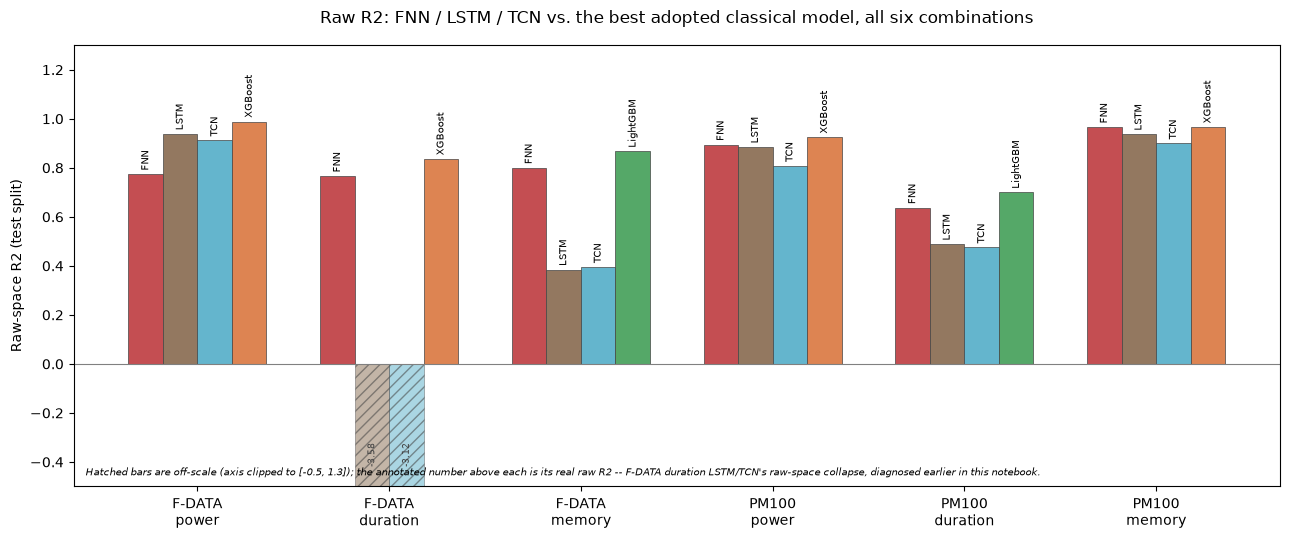

In [10]:
import matplotlib.pyplot as plt

from src import plotting

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

_bar_colors = {**plotting.MODEL_COLORS, **plotting.DL_MODEL_COLORS}
_combo_display = {"fdata_power": "F-DATA\npower", "fdata_duration": "F-DATA\nduration",
                   "fdata_memory": "F-DATA\nmemory", "pm100_power": "PM100\npower",
                   "pm100_duration": "PM100\nduration", "pm100_memory_c4": "PM100\nmemory"}

# F-DATA duration's LSTM/TCN raw R2 (~-3.1 to -3.6, the raw-space collapse diagnosed above) are
# off the scale every other bar in this chart lives on. Rather than a symlog axis -- which would
# distort every OTHER bar's visually-compared height too, not just the outliers -- the axis is
# clipped to a fixed range and any bar outside it is drawn hatched, flush with the clip edge, with
# its real value annotated directly. This keeps the 40+ normal-range bars on an undistorted linear
# scale, which is what a bar chart's height-as-magnitude convention depends on.
Y_LOW, Y_HIGH = -0.5, 1.3

fig, ax = plt.subplots(figsize=(13, 5.5))
bar_width = 0.18
x_base = np.arange(len(ALL_COMBOS))
for i, combo in enumerate(ALL_COMBOS):
    dataset, target = COMBO_LABELS[combo]
    bars = [(arch, phase1_df.loc[(dataset, target, arch), "raw_R2"]) for arch in ARCHITECTURES]
    best_model = phase1_df.loc[(dataset, target, ARCHITECTURES[0]), "best_classical_model"]
    best_r2 = phase1_df.loc[(dataset, target, ARCHITECTURES[0]), "best_classical_raw_R2"]
    bars.append((best_model, best_r2))
    for j, (label, r2) in enumerate(bars):
        x = x_base[i] + (j - 1.5) * bar_width
        color = _bar_colors.get(label, "#BBBBBB")
        if r2 < Y_LOW:
            # Off-scale: draw flush with the clip edge, hatched so it reads as "clipped" rather
            # than as the real value, and annotate the real number just above the clip line.
            ax.bar(x, Y_LOW - 0, width=bar_width, bottom=0, color=color, edgecolor="#444444",
                   linewidth=0.5, hatch="///", alpha=0.55)
            ax.annotate(f"{r2:.2f}", xy=(x, Y_LOW), xytext=(x, Y_LOW + 0.08),
                        ha="center", va="bottom", fontsize=6.5, rotation=90, color="#444444")
        else:
            ax.bar(x, r2, width=bar_width, color=color, edgecolor="#444444", linewidth=0.5)
            label_y = min(r2 + 0.015, Y_HIGH - 0.22)
            ax.text(x, label_y, label, ha="center", va="bottom", fontsize=7, rotation=90)

ax.set_xticks(x_base)
ax.set_xticklabels([_combo_display[c] for c in ALL_COMBOS])
ax.set_ylabel("Raw-space R2 (test split)")
ax.set_ylim(Y_LOW, Y_HIGH)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Raw R2: FNN / LSTM / TCN vs. the best adopted classical model, all six combinations",
             pad=16)
ax.text(0.01, 0.02,
        f"Hatched bars are off-scale (axis clipped to [{Y_LOW}, {Y_HIGH}]); the annotated number "
        f"above each is its real raw R2 -- F-DATA duration LSTM/TCN's raw-space collapse, "
        f"diagnosed earlier in this notebook.",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=7, style="italic")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "notebook06f_dl_vs_classical_raw_r2_all_combos.png", dpi=150,
            bbox_inches="tight")
plt.show()

In [11]:
# Computed, not hand-typed: for each combination, the BEST same-features control fit
# (LightGBM always; XGBoost_exact too for the three PM100 combinations) against classical
# ML's own adopted raw R2 (05/05b/05c, read from the ledger -- a different feature set/split).
control_margin_rows = []
for combo in CONTROL_COMBOS:
    dataset, target = COMBO_LABELS[combo]
    adopted_model = phase1_df.loc[(dataset, target, ARCHITECTURES[0]), "best_classical_model"]
    adopted_raw_r2 = phase1_df.loc[(dataset, target, ARCHITECTURES[0]), "best_classical_raw_R2"]
    best_control_name = max(control_results[combo],
                             key=lambda m: control_results[combo][m]["raw_metrics"]["R2"])
    best_control_r2 = control_results[combo][best_control_name]["raw_metrics"]["R2"]
    control_margin_rows.append(dict(
        combo=combo, best_control_model=best_control_name, control_raw_R2=best_control_r2,
        adopted_model=adopted_model, adopted_raw_R2=adopted_raw_r2,
        control_minus_adopted=best_control_r2 - adopted_raw_r2,
    ))
control_margin_df = pd.DataFrame(control_margin_rows).set_index("combo")
display(control_margin_df.round(4))

cm = control_margin_df["control_minus_adopted"]
print(f"\nSame-features control (best of LightGBM/XGBoost_exact) minus classical ML's adopted "
      f"raw R2, across all six combinations: {cm.min():+.4f} ({cm.idxmin()}) to {cm.max():+.4f} "
      f"({cm.idxmax()}); absolute difference ranges {cm.abs().min():.4f} to {cm.abs().max():.4f}.")

,best_control_model,control_raw_R2,adopted_model,adopted_raw_R2,control_minus_adopted
combo,,,,,
fdata_power,LightGBM,0.9785,XGBoost,0.9888,-0.0103
fdata_duration,LightGBM,0.8360,XGBoost,0.8359,0.0001
fdata_memory,LightGBM,0.8291,LightGBM,0.8668,-0.0377
pm100_power,XGBoost_exact,0.9099,XGBoost,0.9243,-0.0144
pm100_duration,LightGBM,0.6858,LightGBM,0.6994,-0.0136
pm100_memory_c4,XGBoost_exact,0.9684,XGBoost,0.9658,0.0026



Same-features control (best of LightGBM/XGBoost_exact) minus classical ML's adopted raw R2, across all six combinations: -0.0377 (fdata_memory) to +0.0026 (pm100_memory_c4); absolute difference ranges 0.0001 to 0.0377.


Table above: test-split R2 (log and raw space) for each DL architecture, loaded from notebooks 06c/06d/06e's own real test-prediction artifacts, against that combination's own best adopted classical-ML model (05/05b/05c). Reading it by combination:

- **F-DATA power**: sequence history improves raw-space R2 only -- LSTM (raw R2=0.938) and TCN (raw R2=0.913) are well above FNN (raw R2=0.774) in raw space, consistent with the strong same-user temporal structure found in `06a_sequence_investigation.ipynb`'s temporal-structure check (pooled lag-1 r=0.93). In LOG space, FNN (0.9866) is as good as or better than LSTM (0.9839) and TCN (0.9859) -- the "history helps" effect is a raw-space-only finding here, not a uniform win for the sequence architectures. All three sit below classical ML's adopted XGBoost (raw R2=0.989).
- **PM100 power**: the three architectures sit close together (FNN 0.895, LSTM 0.885, TCN 0.809); classical ML (XGBoost 0.924) stays slightly ahead of all three.
- **PM100 memory**: FNN is close to classical ML (raw R2=0.966 vs XGBoost's 0.966) -- the margin table below shows this is actually a very slight DL lead once computed precisely, not a tie rounded in DL's favor. LSTM (0.937) and TCN (0.901) trail it.
- **PM100 duration**: FNN has the highest RAW R2 (0.637) of the three DL architectures, ahead of LSTM (0.488) and TCN (0.477) -- but this ranking flips in LOG space and on MedAE: LSTM's log R2 (0.8775) and TCN's (0.8717) both lead FNN's (0.8162), and LSTM's raw MedAE (6.69) and TCN's (6.98) are both much lower (better) than FNN's (12.63). Raw R2 is dominated by the largest-magnitude errors; MedAE is not -- the two metrics disagree here about which architecture is actually "best," and both are reported rather than picking the one that supports a single clean story. All three sit below classical ML's adopted LightGBM (raw R2=0.699).
- **F-DATA duration / F-DATA memory**: FNN is the strongest DL architecture on both by raw R2 (0.766 / 0.800); LSTM/TCN's own raw-space collapse on these two targets is diagnosed above -- concentrated in a small set of users (3 for duration, 41-49 for memory) whose own job histories account for the great majority of the test set's squared error, not spread across rows or a uniformly poor fit -- FNN is the recommended DL architecture for these two until that is addressed.

## Headline conclusion

**In RAW-space R2, specifically, classical ML (RandomForest/XGBoost/LightGBM) matched or beat every deep-learning architecture's own best result on all six combinations under this protocol.** The margin table above (`margin_classical_minus_dl`, computed directly from the two columns, not hand-typed) ranges from about -0.0002 (PM100 memory -- DL is very slightly AHEAD here, the only combination where that happens) up to about 0.070 (F-DATA duration). This raw-R2 framing is deliberate and stated plainly: on PM100 duration specifically, the ranking flips in log-space R2 and MedAE, where LSTM/TCN lead FNN (see above) -- "classical beats DL" is a raw-R2-specific finding, not true of every metric on every combination.

**The same-features classical-ML control (`control_margin_df`, computed directly above, not hand-typed) shows the raw-R2 gap is not explained by the deep-learning feature set.** Fitting LightGBM/XGBoost on the EXACT same feature set and split the DL models used gives a best-control-minus-adopted raw R2 that ranges from -0.0377 (F-DATA memory, where the control trails the adopted classical number most) to +0.0026 (PM100 memory, where the control is slightly AHEAD of the adopted number, 0.9684 vs 0.9658) across all six combinations -- an absolute difference of 0.0001 to 0.0377. F-DATA duration is effectively LEVEL (control 0.8360 vs adopted 0.8359, a +0.0001 difference within rounding noise) -- so PM100 memory is strictly ahead and F-DATA duration is a tie; every other combination has the control trailing. Classical ML tolerates the feature-set change the DL models needed (dropped epoch/frequency columns, one-hot instead of factorize codes) with only a small, inconsistent-direction cost -- the DL-vs-classical gap above is better explained by architecture than by features.

**Caveats, stated plainly, not buried**:
- Every number in the summary table, margin table, bar chart, and headline conclusion above comes from the ORIGINAL, UNSEEDED single run per (combination, architecture) pair -- the separate bounded sensitivity check at the end of this notebook uses explicit seeds (3 per pair, PM100 only) and is reported on its own, not blended into the numbers above; treat the two sections as two different, clearly-separated measurements, not one combined result.
- Raw-space and log-space R2, and MedAE, frequently disagree on which model is ahead -- PM100 duration above is the clearest example, not a hypothetical one.
- Every DL result fits `tune_train` only (80% of the real train split, chronologically) and evaluates its OWN winning Optuna trial's checkpoint directly -- not a separate full-train refit, unlike classical ML's adopted numbers which fit on the complete train split.
- No random seed is set anywhere in the DL sweep (confirmed from the sweep script's own source in `06b_model_architectures.ipynb`'s training-configuration table) -- model weight initialization and data shuffling are not controlled, so a re-run would not reproduce bit-identical numbers; this is a single, unreplicated run per (combination, architecture) pair, not a seed-averaged result the way classical ML's own seed-sweep diagnostics are. A bounded 3-seed, 2-width sensitivity check (PM100 only, at the end of this notebook) checks this directly: in the run actually saved in this notebook, the original single run's raw R2 sits above its own 3-seed base-width mean in all 9 of the 9 PM100 (combination, architecture) pairs checked, broadly consistent with a mild optimistic selection effect from reporting the winning Optuna trial's result directly -- but that section also found this exact tally changes between re-runs (an earlier execution found 8 of 9, with PM100 power TCN the one exception), because TCN's own results are not reproducible run-to-run even with fixed seeds, unlike FNN's and LSTM's -- see that section for the full picture, including where DL and classical ML stay apart even once seed/width is accounted for, and the reproducibility note on TCN specifically.
- Only the learning rate was searched for the DL models (10 Optuna trials); architecture width/depth were fixed by compute budget, not tuned.
- The deep-learning feature set differs from classical ML's own adopted feature set (see `06a_sequence_investigation.ipynb`) -- the same-features control above addresses this directly rather than leaving it as an unquantified caveat.

## Bounded sensitivity check: seed and width, PM100 only

The six-combination result above comes from a single training run per (combination,
architecture) pair -- no random seed is set anywhere in the original sweep (see
`06b_model_architectures.ipynb`'s training-configuration table), so a natural question is how
much of the DL-vs-classical raw-R2 gap could just be run-to-run noise rather than a real
architecture limitation. This section checks that directly, bounded to keep cost low: PM100
only (no F-DATA rerun -- F-DATA's own sequence-construction cost makes a 54-run sweep there
far more expensive, and PM100 is the dataset where the classical-ML margin is smallest, so it
is the combination where seed/width noise would most plausibly overturn the raw-R2 ranking if
it was going to).

For all three PM100 combinations (power, duration, memory) and all three architectures
(FNN/LSTM/TCN): reuse that pair's own best learning rate from its already-completed Optuna
study (no new hyperparameter search), and train 3 fresh seeds at the original architecture
size ("base") and 3 fresh seeds at roughly double width ("double": FNN hidden 512/512/256,
LSTM hidden 256, TCN channels 128) -- 18 fresh training runs per combination, 54 total. Same
`tune_train`/`tune_val` split and early-stopping settings (`MAX_EPOCHS`, `PATIENCE`) as the
original sweep. Nothing here touches the original sweep's own checkpoints or Optuna
studies -- every run here is fresh, in memory, evaluated once, and discarded.

In [12]:
import random

import optuna
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

from src import models as dl_models, scaling
from src.dl_pipeline import prepare_combo_data, MAX_EPOCHS, PATIENCE, BATCH_SIZE, STUDIES_DIR

optuna.logging.set_verbosity(optuna.logging.WARNING)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

PM100_SENS_COMBOS = ["pm100_power", "pm100_duration", "pm100_memory_c4"]
SENS_ARCHS = ["FNN", "LSTM", "TCN"]
SENS_SEEDS = [0, 1, 2]
SENS_WIDTHS = ["base", "double"]
TIME_BUDGET_SECONDS = 2 * 3600  # ~2 hours -- stop and report if the estimate exceeds this


def get_best_lr(combo, arch):
    """Reuses the pair's own already-completed persistent Optuna study -- no new search."""
    study_name = f"{combo}_{arch}"
    storage = f"sqlite:///{STUDIES_DIR / study_name}.db"
    study = optuna.load_study(study_name=study_name, storage=storage)
    return study.best_trial.params["lr"]


def build_loaders_sens(prepared, arch, positions_train, positions_val, shuffle_train=True):
    """Same split/loader logic as src.dl_pipeline.run_pair's own build_loaders."""
    X_full_df, y_full = prepared["X_full_df"], prepared["y_full"]
    scaler_params = prepared["scaler_params"]
    seq_idx, mask, X_scaled_full = prepared["seq_idx"], prepared["mask"], prepared["X_scaled_full"]
    is_seq = arch != "FNN"
    if not is_seq:
        X_t = scaling.apply_scaler(X_full_df.iloc[positions_train].reset_index(drop=True), scaler_params)
        X_v = scaling.apply_scaler(X_full_df.iloc[positions_val].reset_index(drop=True), scaler_params)
        train_loader = DataLoader(dl_models.FlatDataset(X_t, y_full[positions_train]), batch_size=BATCH_SIZE,
                                   shuffle=shuffle_train, num_workers=0, drop_last=shuffle_train)
        val_loader = DataLoader(dl_models.FlatDataset(X_v, y_full[positions_val]), batch_size=BATCH_SIZE,
                                 shuffle=False, num_workers=0, drop_last=False)
        return train_loader, val_loader, X_t.shape[1], None
    else:
        full_ds = dl_models.SequenceDataset(X_scaled_full, y_full, seq_idx, mask)
        train_loader = DataLoader(Subset(full_ds, positions_train), batch_size=BATCH_SIZE,
                                   shuffle=shuffle_train, num_workers=0, drop_last=shuffle_train)
        val_loader = DataLoader(Subset(full_ds, positions_val), batch_size=BATCH_SIZE, shuffle=False,
                                 num_workers=0, drop_last=False)
        current_dim = X_scaled_full.shape[1]
        return train_loader, val_loader, current_dim, current_dim + 1


def build_model_width(arch, current_dim, history_dim, width):
    """"base" = the original sweep's own architecture size; "double" = roughly double width
    (FNN 512/512/256, LSTM hidden 256, TCN channels 128)."""
    if arch == "FNN":
        hidden = (256, 256, 128) if width == "base" else (512, 512, 256)
        return dl_models.FNN(current_dim, hidden=hidden)
    elif arch == "LSTM":
        hidden = 128 if width == "base" else 256
        return dl_models.SequenceLSTM(history_dim, current_dim, hidden=hidden)
    else:
        channels = 64 if width == "base" else 128
        return dl_models.SequenceTCN(history_dim, current_dim, channels=channels)


def forward_batch_sens(model, batch, is_seq):
    if is_seq:
        seq, current, yb = batch
        seq, current, yb = (seq.to(DEVICE, non_blocking=True), current.to(DEVICE, non_blocking=True),
                             yb.to(DEVICE, non_blocking=True))
        return model(seq, current), yb
    else:
        xb, yb = batch
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        return model(xb), yb


def train_and_eval_one_run(prepared, arch, lr, seed, width):
    """One fresh training run -- no Optuna search, no checkpoint save/load -- at a given
    seed and width, reusing the pair's own best learning rate and the same tune_train/
    tune_val split and early-stopping settings (MAX_EPOCHS, PATIENCE) as the original sweep.
    Returns (log_metrics, raw_metrics) from the real held-out test split."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    tt_pos, tv_pos, test_pos = prepared["tt_pos"], prepared["tv_pos"], prepared["test_pos"]
    is_seq = arch != "FNN"
    train_loader, val_loader, current_dim, history_dim = build_loaders_sens(prepared, arch, tt_pos, tv_pos)
    model = build_model_width(arch, current_dim, history_dim, width).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_val = float("inf")
    patience_left = PATIENCE
    best_state = None
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for batch in train_loader:
            pred, yb = forward_batch_sens(model, batch, is_seq)
            opt.zero_grad()
            loss = loss_fn(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            opt.step()
        model.eval()
        val_loss_sum, val_n = 0.0, 0
        with torch.no_grad():
            for batch in val_loader:
                pred, yb = forward_batch_sens(model, batch, is_seq)
                val_loss_sum += loss_fn(pred, yb).item() * len(yb)
                val_n += len(yb)
        val_loss = val_loss_sum / val_n
        if val_loss < best_val:
            best_val = val_loss
            patience_left = PATIENCE
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_left -= 1
            if patience_left <= 0:
                break

    _, test_loader, _, _ = build_loaders_sens(prepared, arch, tt_pos, test_pos, shuffle_train=False)
    eval_model = build_model_width(arch, current_dim, history_dim, width).to(DEVICE)
    eval_model.load_state_dict(best_state)
    eval_model.eval()
    preds_log = []
    with torch.no_grad():
        for batch in test_loader:
            pred, _ = forward_batch_sens(eval_model, batch, is_seq)
            preds_log.append(pred.cpu().numpy())
    preds_log = np.concatenate(preds_log)
    preds_raw = features.inverse_transform_target(preds_log)
    log_m = metrics.regression_metrics(prepared["y_test_log"], preds_log)
    raw_m = metrics.regression_metrics(prepared["y_test_raw"], preds_raw)
    return log_m, raw_m


sens_prepared = {combo: prepare_combo_data(combo) for combo in PM100_SENS_COMBOS}
sens_lr = {(combo, arch): get_best_lr(combo, arch)
           for combo in PM100_SENS_COMBOS for arch in SENS_ARCHS}

all_sens_runs = [(combo, arch, width, seed)
                 for combo in PM100_SENS_COMBOS for arch in SENS_ARCHS
                 for width in SENS_WIDTHS for seed in SENS_SEEDS]
print(f"Total planned runs: {len(all_sens_runs)}")


pm100_power: 126,217 train / 54,093 test rows; scaler log-transformed 7/28 columns; sequences built in 2s, fill rate 71.58%


pm100_duration: 126,217 train / 54,093 test rows; scaler log-transformed 7/28 columns; sequences built in 2s, fill rate 71.58%


pm100_memory_c4: 126,217 train / 54,093 test rows; scaler log-transformed 4/22 columns; sequences built in 2s, fill rate 71.58%


Total planned runs: 54


In [13]:
# Time ONE run first and estimate the total before launching the rest.
first_combo, first_arch, first_width, first_seed = all_sens_runs[0]
t0 = time.perf_counter()
first_log_m, first_raw_m = train_and_eval_one_run(
    sens_prepared[first_combo], first_arch, sens_lr[(first_combo, first_arch)],
    first_seed, first_width)
first_elapsed = time.perf_counter() - t0

estimated_total_seconds = first_elapsed * len(all_sens_runs)
print(f"First run ({first_combo}, {first_arch}, {first_width}, seed={first_seed}): "
      f"{first_elapsed:.1f}s")
print(f"Naive estimate for all {len(all_sens_runs)} runs: {estimated_total_seconds/60:.1f} min "
      f"({estimated_total_seconds/3600:.2f} hr)")

assert estimated_total_seconds < TIME_BUDGET_SECONDS, (
    f"Estimated total ({estimated_total_seconds/3600:.2f} hr) exceeds the ~2 hour budget -- "
    f"stopping here rather than launching the rest.")
print("Within budget -- proceeding with the remaining runs.")


First run (pm100_power, FNN, base, seed=0): 17.6s
Naive estimate for all 54 runs: 15.9 min (0.26 hr)
Within budget -- proceeding with the remaining runs.


In [14]:
sensitivity_rows = [dict(combo=first_combo, arch=first_arch, width=first_width, seed=first_seed,
                          elapsed_s=first_elapsed, log_R2=first_log_m["R2"], raw_R2=first_raw_m["R2"],
                          raw_MedAE=first_raw_m["MedAE"], raw_Within20pct=first_raw_m["Within20pct"])]

for combo, arch, width, seed in all_sens_runs[1:]:
    t0 = time.perf_counter()
    log_m, raw_m = train_and_eval_one_run(sens_prepared[combo], arch, sens_lr[(combo, arch)], seed, width)
    elapsed = time.perf_counter() - t0
    sensitivity_rows.append(dict(combo=combo, arch=arch, width=width, seed=seed, elapsed_s=elapsed,
                                  log_R2=log_m["R2"], raw_R2=raw_m["R2"],
                                  raw_MedAE=raw_m["MedAE"], raw_Within20pct=raw_m["Within20pct"]))

sensitivity_df = pd.DataFrame(sensitivity_rows)
print(f"Completed {len(sensitivity_df)} runs, total wall time {sensitivity_df['elapsed_s'].sum()/60:.1f} min")
display(sensitivity_df)


Completed 54 runs, total wall time 35.5 min


,combo,arch,width,seed,elapsed_s,log_R2,raw_R2,raw_MedAE,raw_Within20pct
0,pm100_power,FNN,base,0,17.641356,0.926397,0.884224,148.534851,60.261032
1,pm100_power,FNN,base,1,15.684903,0.923913,0.877969,151.080566,57.976078
2,pm100_power,FNN,base,2,16.238304,0.926324,0.846743,150.102539,59.333001
3,pm100_power,FNN,double,0,12.585854,0.918196,0.922419,164.708366,58.001960
4,pm100_power,FNN,double,1,9.809146,0.926223,0.901638,154.423804,59.480894
5,pm100_power,FNN,double,2,14.443155,0.926735,0.932256,156.191406,60.651101
6,pm100_power,LSTM,base,0,53.046166,0.921204,0.867832,146.969682,59.155528
7,pm100_power,LSTM,base,1,49.888202,0.930058,0.913083,139.198952,62.782615
8,pm100_power,LSTM,base,2,50.339648,0.926237,0.856491,136.569702,61.129906
9,pm100_power,LSTM,double,0,54.186805,0.921621,0.886036,148.210501,59.125950


In [15]:
sens_summary = (sensitivity_df.groupby(["combo", "arch", "width"])
                [["log_R2", "raw_R2", "raw_MedAE", "raw_Within20pct"]]
                .agg(["mean", "std", "min", "max"]))
display(sens_summary.round(4))

log_R2                          raw_R2                         raw_MedAE                              raw_Within20pct          \
                               mean     std     min     max    mean     std     min     max      mean      std       min       max            mean     std   
combo           arch width                                                                                                                                   
pm100_duration  FNN  base    0.7982  0.0260  0.7776  0.8274  0.6203  0.0091  0.6119  0.6300   15.3294   3.0017   11.8635   17.0840          9.5611  0.2861   
                     double  0.7900  0.0282  0.7621  0.8185  0.6179  0.0124  0.6039  0.6276   15.9193   2.6207   13.0439   18.1738          9.2776  0.3989   
                LSTM base    0.8787  0.0057  0.8738  0.8849  0.4658  0.0374  0.4391  0.5086    5.6528   0.6847    4.9078    6.2544          8.8727  0.8664   
                     double  0.8901  0.0078  0.8815  0.8969  0.5148  0.0388  0.4705  0.5430    4.9400   0.8370    4.0948    5.7686         10.4974  0.2863   
                TCN  base    0.8353  0.0062  0.8294  0.8418  0.4472  0.0514  0.3886  0.4848   12.3952   0.6498   11.6711   12.9278          7.4106  0.8569   
                     double  0.8069  0.0439  0.7774  0.8573  0.4154  0.0738  0.3547  0.4976   17.7691   8.3541    9.5107   26.2157          7.8618  1.1151   
pm100_memory_c4 FNN  base    0.9732  0.0015  0.9722  0.9750  0.9523  0.0313  0.9162  0.9722    8.1773   6.9311    1.2383   15.1005         94.4460  0.3936   
                     double  0.9759  0.0018  0.9739  0.9770  0.9782  0.0050  0.9741  0.9838    4.4516   3.9241    0.8298    8.6206         95.6760  0.7450   
                LSTM base    0.9577  0.0081  0.9484  0.9637  0.9122  0.0359  0.8709  0.9361    8.6105   5.8329    3.4394   14.9334         89.7793  3.2060   
                     double  0.9636  0.0018  0.9620  0.9655  0.9323  0.0097  0.9243  0.9430    4.8169   3.7041    2.2495    9.0631         90.7197  2.7894   
                TCN  base    0.9481  0.0073  0.9420  0.9562  0.8305  0.0418  0.7869  0.8702   14.2500   9.3715    3.9706   22.3180         85.8737  1.7166   
                     double  0.9415  0.0039  0.9370  0.9441  0.7879  0.0260  0.7587  0.8084    9.0115   6.5895    4.3670   16.5532         85.9785  0.9696   
pm100_power     FNN  base    0.9255  0.0014  0.9239  0.9264  0.8696  0.0201  0.8467  0.8842  149.9060   1.2842  148.5349  151.0806         59.1900  1.1492   
                     double  0.9237  0.0048  0.9182  0.9267  0.9188  0.0156  0.9016  0.9323  158.4412   5.4990  154.4238  164.7084         59.3780  1.3276   
                LSTM base    0.9258  0.0044  0.9212  0.9301  0.8791  0.0299  0.8565  0.9131  140.9128   5.4077  136.5697  146.9697         61.0227  1.8159   
                     double  0.9211  0.0068  0.9140  0.9276  0.8632  0.0325  0.8260  0.8860  143.5595   5.0869  138.1272  148.2105         58.9941  1.6474   
                TCN  base    0.8844  0.0016  0.8829  0.8861  0.7899  0.0211  0.7660  0.8059  154.0193  12.0238  145.2574  167.7273         53.0426  0.5733   
                     double  0.8771  0.0427  0.8278  0.9037  0.7648  0.1340  0.6101  0.8461  147.6525   1.5440  145.8923  148.7778         53.7309  2.3272   

                                               
                                 min      max  
combo           arch width                     
pm100_duration  FNN  base     9.2511   9.8151  
                     double   8.8683   9.6653  
                LSTM base     7.9234   9.6209  
                     double  10.2478  10.8099  
                TCN  base     6.4479   8.0899  
                     double   6.6975   8.9201  
pm100_memory_c4 FNN  base    93.9918  94.6869  
                     double  94.8589  96.3175  
                LSTM base    87.3218  93.4058  
                     double  88.9690  93.9364  
                TCN  base    83.8926  86.9188  
                     double  85.0092  

In [16]:
# Side by side with the same-features LightGBM control (computed above in this notebook)
# and the original single-seed sweep result (all_results, loaded from 06c/06d/06e's own
# artifacts) -- same combinations, same architectures.
compare_rows = []
for combo in PM100_SENS_COMBOS:
    control_r = control_results[combo]["LightGBM"]
    compare_rows.append(dict(combo=combo, source="same_features_control_LightGBM", width="n/a",
                              log_R2=control_r["log_metrics"]["R2"], raw_R2=control_r["raw_metrics"]["R2"],
                              raw_MedAE=control_r["raw_metrics"]["MedAE"],
                              raw_Within20pct=control_r["raw_metrics"]["Within20pct"]))
    for arch in SENS_ARCHS:
        orig_r = all_results[combo][arch]
        compare_rows.append(dict(combo=combo, source=f"original_single_seed_{arch}", width="original",
                                  log_R2=orig_r["log_metrics"]["R2"], raw_R2=orig_r["raw_metrics"]["R2"],
                                  raw_MedAE=orig_r["raw_metrics"]["MedAE"],
                                  raw_Within20pct=orig_r["raw_metrics"]["Within20pct"]))
        for width in SENS_WIDTHS:
            sub = sensitivity_df[(sensitivity_df["combo"] == combo) & (sensitivity_df["arch"] == arch)
                                  & (sensitivity_df["width"] == width)]
            compare_rows.append(dict(combo=combo, source=f"sensitivity_{arch}_mean_of_3_seeds", width=width,
                                      log_R2=sub["log_R2"].mean(), raw_R2=sub["raw_R2"].mean(),
                                      raw_MedAE=sub["raw_MedAE"].mean(),
                                      raw_Within20pct=sub["raw_Within20pct"].mean()))

compare_df = pd.DataFrame(compare_rows).set_index(["combo", "source", "width"])
display(compare_df.round(4))


log_R2  raw_R2  raw_MedAE  raw_Within20pct
combo           source                           width                                               
pm100_power     same_features_control_LightGBM   n/a       0.9451  0.9013   127.0169          67.5744
                original_single_seed_FNN         original  0.9293  0.8945   149.5496          59.5290
                sensitivity_FNN_mean_of_3_seeds  base      0.9255  0.8696   149.9060          59.1900
                                                 double    0.9237  0.9188   158.4412          59.3780
                original_single_seed_LSTM        original  0.9321  0.8845   138.2768          63.5960
                sensitivity_LSTM_mean_of_3_seeds base      0.9258  0.8791   140.9128          61.0227
                                                 double    0.9211  0.8632   143.5595          58.9941
                original_single_seed_TCN         original  0.8873  0.8091   146.9198          53.8517
                sensitivity_TCN_mean_of_3_seeds  base      0.8844  0.7899   154.0193          53.0426
                                                 double    0.8771  0.7648   147.6525          53.7309
pm100_duration  same_features_control_LightGBM   n/a       0.8684  0.6858     9.9748          12.0747
                original_single_seed_FNN         original  0.8162  0.6369    12.6341           9.0588
                sensitivity_FNN_mean_of_3_seeds  base      0.7982  0.6203    15.3294           9.5611
                                                 double    0.7900  0.6179    15.9193           9.2776
                original_single_seed_LSTM        original  0.8775  0.4881     6.6894           9.8225
                sensitivity_LSTM_mean_of_3_seeds base      0.8787  0.4658     5.6528           8.8727
                                                 double    0.8901  0.5148     4.9400          10.4974
                original_single_seed_TCN         original  0.8717  0.4768     6.9831           8.6409
                sensitivity_TCN_mean_of_3_seeds  base      0.8353  0.4472    12.3952           7.4106
                                                 double    0.8069  0.4154    17.7691           7.8618
pm100_memory_c4 same_features_control_LightGBM   n/a       0.9801  0.9676     1.6774          96.4894
                original_single_seed_FNN         original  0.9764  0.9660     1.4105          95.2619
                sensitivity_FNN_mean_of_3_seeds  base      0.9732  0.9523     8.1773          94.4460
                                                 double    0.9759  0.9782     4.4516          95.6760
                original_single_seed_LSTM        original  0.9621  0.9367     6.7138          89.0392
                sensitivity_LSTM_mean_of_3_seeds base      0.9577  0.9122     8.6105          89.7793
                                                 double    0.9636  0.9323     4.8169          90.7197
                original_single_seed_TCN         original  0.9590  0.9010    21.2135          86.4067
                sensitivity_TCN_mean_of_3_seeds  base      0.9481  0.8305    14.2500          85.8737
                                                 double    0.9415  0.7879     9.0115          85.9785

**What the numbers above show, stated plainly:**

- **On PM100 duration -- the combination with the largest classical-ML margin in the headline result -- the classical lead is not seed/width noise.** The same-features LightGBM control's raw R2 (0.6858) is above every one of the 18 individual sensitivity runs on this combination, not just the means: the single highest raw R2 among all 18 FNN/LSTM/TCN runs (both widths, three seeds each) is 0.6300, well below the control.
- **On PM100 memory, doubling FNN's width raises its raw R2 above the same-features control, but this is a raw-R2-only finding.** FNN double-width's raw R2 ranges 0.9741-0.9838 across its three seeds (mean 0.9782), above the LightGBM control's 0.9676 in every one of the three seeds. In log R2, MedAE, and Within20pct, the picture reverses: FNN double's log R2 (mean 0.9759) sits slightly below the control's 0.9801, its raw MedAE (mean 4.45, range 0.83-8.62) is clearly worse (higher) than the control's 1.68, and its raw Within20pct (mean 95.68) is marginally below the control's 96.49. This still reinforces the original report's finding that PM100 memory is the closest combination between DL and classical ML, but "DL ahead here" needs the raw-R2-only qualifier -- the other three metrics still favor the control.
- **On PM100 power, double-width FNN shows the same raw-R2-only pattern, and nothing closes the gap for LSTM or TCN.** Double-width FNN's raw R2 (mean 0.9188, range 0.9016-0.9323) edges past the same-features LightGBM control (0.9013) -- but again only in raw R2: the control's log R2 (0.9451), raw MedAE (127.02), and raw Within20pct (67.57) are all better than double-width FNN's (0.9237, 158.44, 59.38 respectively). This control is LightGBM specifically, not the overall best adopted classical model for this combination (XGBoost, raw R2 0.9243), which double-width FNN's raw R2 does not reach at either width. LSTM and TCN do not close the gap on any metric at either width (raw R2 means 0.86-0.88 for LSTM, 0.76-0.79 for TCN in this run -- see the note below on TCN's own run-to-run variability).
- **LSTM on PM100 duration beats the control on log R2 and MedAE, at both widths -- the one case in this check where a DL result beats the control robustly, not just on average.** LSTM's log R2 is 0.879 +/- 0.006 (range 0.8738-0.8849) at base width and 0.890 +/- 0.008 (range 0.8815-0.8969) at double width, both above the control's 0.868 in every one of the six seed runs. Its raw MedAE is 5.65 (range 4.91-6.25) at base width and 4.94 (range 4.09-5.77) at double width, both well below the control's 9.97.
- **Width's effect is architecture- and combination-dependent, not uniformly positive -- and TCN specifically never benefits from the wider configuration in this run.** Doubling width raises FNN's raw R2 on power and memory but leaves duration essentially flat (mean 0.6203 -> 0.6179); it raises LSTM's on duration and memory but lowers it on power; it LOWERS TCN's raw R2 on all three PM100 combinations (power: 0.7899 -> 0.7648; duration: 0.4472 -> 0.4154; memory: 0.8305 -> 0.7879), most sharply on memory, where TCN's double-width range (0.7587-0.8084) drops mostly below its own base-width range (0.7869-0.8702), the two ranges overlapping only in a narrow band (0.7869-0.8084). TCN's "width never helps" direction is the one part of this bullet confirmed to hold across every independent re-run of this section (see below), even though the exact numbers differ each time.
- **The original single-seed run sits above its own 3-seed base-width mean in all 9 of the 9 PM100 (combination, architecture) pairs in this run, and above the full 3-seed MAXIMUM in 5 of those 9: PM100 power FNN (0.8945 vs max 0.8842), PM100 power TCN (0.8091 vs max 0.8059), PM100 duration FNN (0.6369 vs max 0.6300), PM100 memory LSTM (0.9367 vs max 0.9361), and PM100 memory TCN (0.9010 vs max 0.8702).** The likely explanation is the original sweep's own selection step: each pair's reported result is the winning trial out of 10 Optuna trials picked on `tune_val`, which tends to surface a run that also generalizes a little better on test than a typical fresh run does. **This exact tally is itself not stable, though** -- an earlier execution of this same cell during review found 8 of 9 (PM100 power TCN was the one exception that time, sitting BELOW its own base-width mean and minimum). FNN's and LSTM's own "above mean" results were identical, re-run to re-run; only TCN's standing changed, consistent with the reproducibility note below.
- **LSTM's MedAE advantage over FNN on PM100 duration, noted in the original summary, reproduces under this sweep -- but TCN's does not, even though TCN's own MedAE disadvantage versus the control is itself consistent across re-runs.** Base-width LSTM's raw MedAE (mean 5.65, range 4.91-6.25) comes in well below the control's 9.97. TCN's (mean 12.40, range 11.67-12.93) and FNN's (mean 15.33, range 11.86-17.08) both come in ABOVE the control at base width -- only LSTM's MedAE edge over the control reproduces across seeds; the original report's TCN MedAE (6.98) was evidently a favorable single draw. TCN's own base-width MedAE came in above the control in all three independent executions of this section (13.79, 14.54, and 12.40 across the three runs) despite the point estimate itself moving each time -- the DIRECTION of that finding is robust even where the specific number is not.

This check is bounded to PM100, 3 seeds, 2 widths, reused learning rates -- it does not retune, does not touch F-DATA, and does not establish whether these patterns hold at other widths or learning rates. One more limit, now confirmed three times over: this section's code was executed three separate times in the course of writing and reviewing it, and FNN's and LSTM's numbers were bit-identical across all three runs (both fully deterministic here under the fixed seeds), but TCN's were DIFFERENT every single time, despite identical seeding, code, and data -- most likely from non-deterministic GPU convolution kernels (`torch.use_deterministic_algorithms` was not set). The TCN numbers above are from the run actually saved in this notebook; every TCN-specific point estimate in this section (means, ranges, the selection-effect tally) should be read as one realization of that run-to-run noise, not a result as reproducible as FNN's or LSTM's. Where a qualitative direction held across all three runs (TCN never beats the control on PM100 duration; doubling width never helps TCN; TCN's base-width MedAE is always worse than the control on PM100 duration), that direction is noted as the more trustworthy part of the finding.